# 05 - Backtest: do park effects predict home vs. road results?

For every pitcher-season, compare how hitters did against him at his home park versus on the road, then check whether the model predicted that gap.

- **Observed gap:** mean (actual - expected) wOBA on contact at home minus on the road. Positive means hitters did better at home.
- **Predicted gap:** the same difference using park effects estimated **only from other seasons** (leave-one-season-out), so the model never sees the season it is predicting.
- **Park-factor baseline:** the same, but with one park-wide number per park instead of effects by batter side and batted-ball type.

The question: does the batted-ball model predict the gap better than a plain park factor? A pitcher's batted-ball mix and handedness are what make the two predictions differ. If the model beats the baseline, the pitcher-specific part adds real information.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.config import PROCESSED, INTERIM, FIGURES
from src.data import load_seasons
from src.park_effects import contact_frame
from src.backtest import add_home_flag, attach_loso_effects, home_road_table, evaluate, calibration_table
from src.plots import plot_calibration

df = pd.read_parquet(INTERIM / "pitches_archetyped.parquet")
contact = contact_frame(df)

# Which half of the inning a pitcher worked tells us whether the game was at his home park
side = load_seasons(columns=["game_pk", "pitcher", "inning_topbot"])
contact = add_home_flag(contact, side)
print(f"{len(contact):,} balls in play with a home/road flag; {contact['is_home'].mean():.1%} at home")

611,324 balls in play with a home/road flag; 50.9% at home


## Predict each season from the other seasons

In [2]:
test = attach_loso_effects(contact)
table = home_road_table(test, min_bip=100)
print(f"{len(table)} pitcher-seasons with 100+ balls in play both at home and on the road")
table.head()

607,262 balls in play kept (4,062 dropped: park has no data in the other seasons)
849 pitcher-seasons with 100+ balls in play both at home and on the road


,pitcher,game_year,bip_road,bip_home,gap_road,gap_home,full_road,full_home,park_road,park_home,obs,pred_full,pred_park,extra,weight
0,425794,2022,258,337,-0.021664,-0.032634,-0.000067,-0.015889,0.00071,-0.016023,-0.01097,-0.015822,-0.016734,0.000912,146.127731
1,425794,2023,171,184,0.06059,-0.004941,0.000322,-0.017541,-0.001753,-0.01619,-0.06553,-0.017862,-0.014437,-0.003425,88.630986
2,425844,2022,237,220,0.022956,-0.039814,0.002195,-0.006435,0.001414,-0.010905,-0.06277,-0.00863,-0.012319,0.003689,114.091904
3,425844,2023,211,257,0.017574,-0.009549,-0.001403,-0.006436,-0.001558,-0.009655,-0.027123,-0.005033,-0.008097,0.003064,115.869658
4,434378,2022,225,217,-0.061124,-0.020782,-0.006899,0.007448,-0.007487,0.010041,0.040342,0.014346,0.017527,-0.003181,110.463801


## Results

In [3]:
res = evaluate(table)
print(f"{res['n']} pitcher-seasons")
print(f"Correlation with the observed home-road gap: park factor only {res['corr_park']:.2f} | batted-ball model {res['corr_full']:.2f}"
      f" (difference 90% interval {res['corr_gain_lo']:.3f} to {res['corr_gain_hi']:.3f})")
print(f"Weighted R^2: park factor only {res['r2_park']:.3f} | adding the pitcher-specific part {res['r2_both']:.3f}")
print(f"R^2 gain from the pitcher-specific part: {res['r2_gain']:.3f} (90% interval {res['r2_gain_lo']:.3f} to {res['r2_gain_hi']:.3f})")
print(f"Slope of observed on predicted (1.0 = effect size is right): {res['slope_full']:.2f}")
print(f"Weight on the pitcher-specific part (0 = nothing, 1 = model exactly right): {res['extra_weight']:.2f} "
      f"(90% interval {res['extra_weight_lo']:.2f} to {res['extra_weight_hi']:.2f})")
print(f"That part varies {res['extra_sd_pts']:.1f} pts between pitchers; the observed gap varies {res['obs_sd_pts']:.1f} pts")
pd.DataFrame([res]).round(4).to_csv(PROCESSED / "backtest_results.csv", index=False)

849 pitcher-seasons
Correlation with the observed home-road gap: park factor only 0.21 | batted-ball model 0.20 (difference 90% interval -0.016 to 0.007)
Weighted R^2: park factor only 0.043 | adding the pitcher-specific part 0.043
R^2 gain from the pitcher-specific part: 0.000 (90% interval 0.000 to 0.004)
Slope of observed on predicted (1.0 = effect size is right): 0.82
Weight on the pitcher-specific part (0 = nothing, 1 = model exactly right): 0.09 (90% interval -0.90 to 0.99)
That part varies 3.0 pts between pitchers; the observed gap varies 49.4 pts


**How to read this**

- If the interval for the R^2 gain is entirely above zero, the pitcher-specific part adds real predictive information beyond a plain park factor. If it includes zero, the model's edge over a park factor is not established, and that is what the write-up should say.
- A slope well below 1 means the predictions are too large (overconfident); well above 1 means too small.
- Even a good result will have modest R^2: a pitcher's home-road gap on contact is mostly luck over a single season.

 bin  pitcher_seasons  predicted_pts  observed_pts
   0              170          -13.3         -14.2
   1              170           -6.2          -9.7
   2              169           -1.9          -9.2
   3              170            2.7          -4.7
   4              170           19.4           9.3


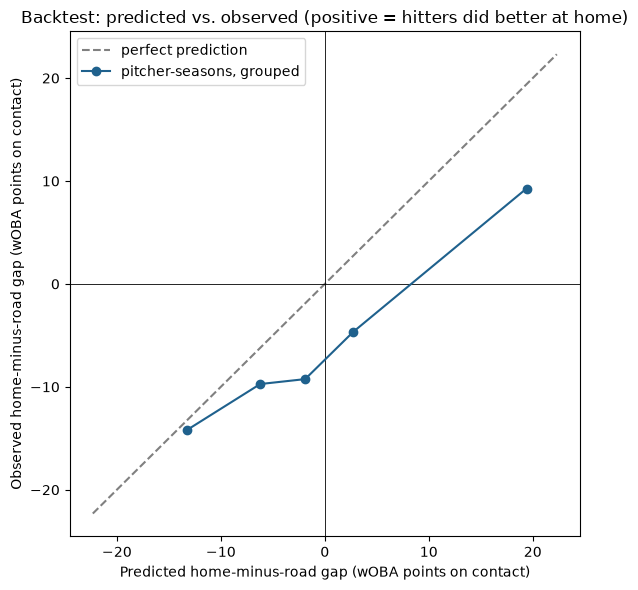

In [4]:
cal = calibration_table(table)
print(cal.round(1).to_string(index=False))
plot_calibration(cal, path=FIGURES / "backtest_calibration.png")
plt.show()

## Commit

```
git add notebooks/05_backtest.ipynb data/processed slides/figures
git commit -m "add home vs road backtest"
git push
```